# Solutions to the exercises of Chapter 9

Sample solutions for [Chapter 9, A drying droplet](../../notebooks/part2_liquids_interfaces/09_drying_droplet.ipynb).

The cell below repeats the model of Section 9.3, Eq. (9.8), with two options: the
evaporation law, and whether $k_{\rm cl}$ or $\xi_{\rm cl}$ is held constant. Units are
$R_0$, $V_0$ and $\tau_{\rm ev}$, and the deposit is computed from Eq. (9.10) as in the
chapter.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp

try:
    import onsager as on
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import onsager as on

on.use_style()
LOG_H0_OVER_B = math.log(1e5)

def drying(k_cl, k_ev, law="flux", constant="k", n_t=12000):
    """law: 'flux' (dV/dt = -R^2) or 'diffusion' (dV/dt = -R); constant: 'k' or 'xi'."""
    ell0 = LOG_H0_OVER_B - 1
    def rhs(t, y):
        R, V = y[0], y[1]
        q = V / R**3
        ell = LOG_H0_OVER_B + math.log(V / R**2) - 1
        Vdot = -R**2 if law == "flux" else -R
        k = k_cl if constant == "k" else k_cl * q * ell0 / ell
        capillary = q * (q * q - 1) / (6 * ell * k_ev) if np.isfinite(k_ev) else 0.0
        Rdot = (R * Vdot / (4 * V) + capillary) / (1 + k)
        return [Rdot, Vdot, Rdot / R - Vdot / (4 * V)]
    thin = lambda t, y: y[1] / y[0] ** 2 - 10 * math.exp(-LOG_H0_OVER_B)
    thin.terminal = True
    sol = solve_ivp(rhs, (0, 50), [1.0, 1.0, 0.0], events=thin, dense_output=True, rtol=1e-11, atol=1e-14, method="LSODA")
    T = sol.t[-1]
    t = np.concatenate((np.linspace(0, 0.99 * T, n_t // 2), T * (1 - np.logspace(-2, -10, n_t // 2))))
    R, V, W = sol.sol(t)
    return dict(t=t, R=R, V=V, W=W)

def deposit(run, n=4000):
    t, R, W = run["t"], run["R"], run["W"]
    r0 = (np.arange(n) + 0.5) / n
    reach = R * np.exp(-W)
    caught = r0 > reach[-1]
    order = np.argsort(reach)
    rf = r0 * np.exp(W[-1])
    rf[caught] = np.interp(np.interp(r0[caught], reach[order], t[order]), t, R)
    return r0, rf, (1 - r0**2) * r0 / (rf * np.gradient(rf, r0))

def peak(run):
    r0, rf, mu = deposit(run)
    return rf[np.argmax(mu)]

def peak_fast(k):
    return (k / (2 * k + 1)) ** (1 / (2 * (1 + k)))

## Exercise 1. Diffusion-limited evaporation

In the fast-evaporation limit the capillary term of Eq. (9.6) is dropped and
$\dot R = R\dot V/4V(1 + k_{\rm cl})$. The solute then moves as

$$ \frac{\dot{\tilde r}}{\tilde r} = \frac{\dot R}{R} - \frac{\dot V}{4V} = \frac{\dot R}{R} - (1 + k_{\rm cl})\frac{\dot R}{R} = -k_{\rm cl}\,\frac{\dot R}{R} . $$

Neither equation contains the evaporation law; only the ratio $\dot V/V$ appears, and
it is eliminated in favour of $\dot R/R$. Any law gives the same paths
$\tilde r R^{k_{\rm cl}} = r_0$, hence the same deposit (9.11). The law matters only through
the capillary term, that is, at finite $k_{\rm ev}$.

In [2]:
ks = [0.1, 0.3, 1.0, 3.0, 10.0]
print("peak r_p/R0 for k_cl =             " + "  ".join(f"{k:6.2f}" for k in ks))
print("  Eq. (9.11)                       " + "  ".join(f"{peak_fast(k):6.3f}" for k in ks))
for law in ("flux", "diffusion"):
    print(f"  {law:9s} k_ev -> infinity       " + "  ".join(f"{peak(drying(k, np.inf, law)):6.3f}" for k in ks))
for k_ev in (0.1, 0.01):
    for law in ("flux", "diffusion"):
        print(f"  {law:9s} k_ev = {k_ev:<5}          " + "  ".join(f"{peak(drying(k, k_ev, law)):6.3f}" for k in ks))

peak r_p/R0 for k_cl =               0.10    0.30    1.00    3.00   10.00
  Eq. (9.11)                        0.323   0.525   0.760   0.900   0.967
  flux      k_ev -> infinity        0.323   0.525   0.760   0.900   0.967
  diffusion k_ev -> infinity        0.324   0.525   0.760   0.899   0.967


  flux      k_ev = 0.1             0.176   0.416   0.707   0.878   0.960
  diffusion k_ev = 0.1             0.260   0.458   0.716   0.880   0.960


  flux      k_ev = 0.01            0.000   0.000   0.000   0.695   0.909
  diffusion k_ev = 0.01            0.047   0.118   0.373   0.726   0.911


In the fast limit both laws give Eq. (9.11). At $k_{\rm ev} = 0.1$ and 0.01 the
diffusion-limited law gives peaks a little further out. Its evaporation rate falls
only as $R$, not $R^2$, so the late stages of drying are faster compared with the
capillary relaxation, and the drop behaves as if $k_{\rm ev}$ were larger.

## Exercise 2. A pinned drop

With $\dot R = 0$, Eq. (9.9) gives $\dot{\tilde r}/\tilde r = -\dot V/4V$, so
$\tilde r = r_0(V/V_0)^{-1/4}$. The element reaches the edge, $\tilde r = R_0$, when
$V/V_0 = (r_0/R_0)^4$. The solute that started outside $r_0$ is
$\int_{r_0}^{R_0}2\pi r\,\phi_0H_0(1 - r^2/R_0^2)\,dr = \tfrac{\pi}{2}\phi_0H_0R_0^2\,(1 - r_0^2/R_0^2)^2$,
a fraction $(1 - r_0^2/R_0^2)^2$ of the whole. With $r_0/R_0 = (V/V_0)^{1/4}$ the
fraction at the edge is

$$ f = \big(1 - \sqrt{V/V_0}\big)^2 . $$

With a constant flux and a pinned edge, $V/V_0 = 1 - t/\tau_{\rm ev}$, and early on
$f \simeq (t/2\tau_{\rm ev})^2$. The cell checks this against the model with a very large
line friction.

V/V0 = 0.900: fraction at the edge 0.0026   (1 - sqrt V)^2 = 0.0026
V/V0 = 0.500: fraction at the edge 0.0857   (1 - sqrt V)^2 = 0.0858
V/V0 = 0.100: fraction at the edge 0.4673   (1 - sqrt V)^2 = 0.4675
V/V0 = 0.010: fraction at the edge 0.8100   (1 - sqrt V)^2 = 0.8099


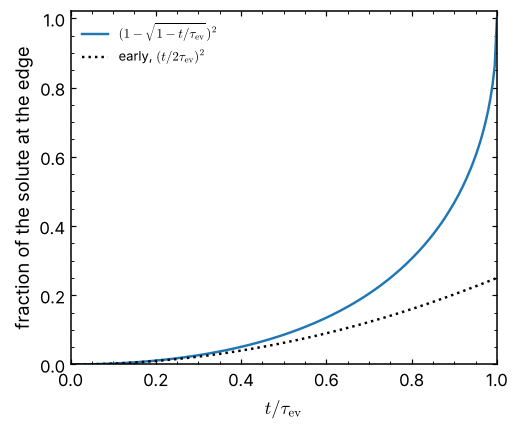

In [3]:
run = drying(1e6, np.inf)
r0, rf, mu = deposit(run)
reach = run["R"] * np.exp(-run["W"])
for V in (0.9, 0.5, 0.1, 0.01):
    i = np.argmin(np.abs(run["V"] - V))
    computed = np.sum((2 * np.pi * r0 * (1 - r0**2) / len(r0))[r0 > reach[i]]) / (math.pi / 2)
    print(f"V/V0 = {run['V'][i]:.3f}: fraction at the edge {computed:.4f}   (1 - sqrt V)^2 = {(1 - math.sqrt(run['V'][i])) ** 2:.4f}")

fig, ax = plt.subplots(figsize=(4.6, 3.8))
tt = np.linspace(0, 1, 200)
ax.plot(tt, (1 - np.sqrt(1 - tt)) ** 2, "C0", label=r"$(1 - \sqrt{1 - t/\tau_{\rm ev}})^2$")
ax.plot(tt, tt**2 / 4, "k:", label=r"early, $(t/2\tau_{\rm ev})^2$")
ax.set_xlabel(r"$t/\tau_{\rm ev}$"); ax.set_ylabel("fraction of the solute at the edge")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.legend(loc="upper left", fontsize=8.5)
plt.show()

**Figure S9.1.** Growth of the ring for a pinned drop with a uniform evaporation flux.

The ring grows slowly at first and collects most of the solute only at the end:
half of it when 17 % of the liquid is left. With a uniform flux, the outward flow
exists only because the thin edge loses a larger fraction of its liquid than the
centre. When evaporation is limited by diffusion in still air, the flux is largest
at the edge itself, and liquid flows towards the edge strongly from the start. The
ring then grows faster at early times than the $t^2$ found here.

## Exercise 3. Slow evaporation

When $k_{\rm ev} \to 0$ the capillary term of Eq. (9.6) dominates unless $\theta = \theta_e$:
any departure is corrected at once, whatever the line friction (which only adds a
small lag). So $V/R^3$ stays constant, $R = R_0(V/V_0)^{1/3}$, and

$$ \frac{\dot{\tilde r}}{\tilde r} = \frac{\dot R}{R} - \frac{\dot V}{4V} = \frac{\dot V}{3V} - \frac{\dot V}{4V} = \frac{\dot V}{12V} < 0 : $$

the solute moves inwards, $\tilde r = r_0(V/V_0)^{1/12}$. It is caught when
$r_0(V/V_0)^{1/12} = R_0(V/V_0)^{1/3}$, that is, at $V/V_0 = (r_0/R_0)^4$, at the radius
$r = R_0(r_0/R_0)^{4/3}$. With Eq. (9.10), $r_0 = r^{3/4}$ and $dr_0/dr = \tfrac34r^{-1/4}$
(in units of $R_0$),

$$ \mu = \phi_0H_0\,(1 - r^{3/2})\,\frac{r^{3/4}}{r}\,\frac34 r^{-1/4} = \frac34\,\phi_0H_0\,r^{-1/2}\,\big(1 - r^{3/2}\big) . $$

The deposit diverges at the centre: a mountain, with a peak more pronounced than the
shape of the drop.

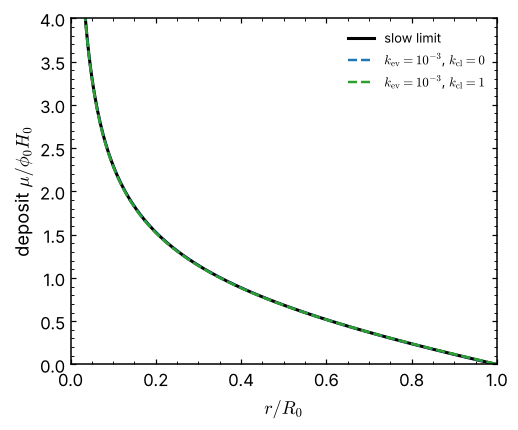

k_ev = 1e-3, k_cl = 0: largest relative difference from the slow limit for 0.15 < r < 0.95: 0.015


In [4]:
fig, ax = plt.subplots(figsize=(4.6, 3.8))
rr = np.linspace(0.01, 1, 300)
ax.plot(rr, 0.75 * rr**-0.5 * (1 - rr**1.5), "k-", lw=2, label="slow limit")
for k, color in ((0.0, "C0"), (1.0, "C2")):
    r0, rf, mu = deposit(drying(k, 1e-3))
    ax.plot(rf, mu, "--", color=color, label=rf"$k_{{\rm ev}} = 10^{{-3}}$, $k_{{\rm cl}} = {k:g}$")
ax.set_xlabel("$r/R_0$"); ax.set_ylabel(r"deposit $\mu/\phi_0H_0$")
ax.set_xlim(0, 1); ax.set_ylim(0, 4); ax.legend(loc="upper right", fontsize=8.5)
plt.show()
r0, rf, mu = deposit(drying(0.0, 1e-3))
inside = (rf > 0.15) & (rf < 0.95)
print(f"k_ev = 1e-3, k_cl = 0: largest relative difference from the slow limit for 0.15 < r < 0.95:"
      f" {np.max(np.abs(mu[inside] / (0.75 * rf[inside] ** -0.5 * (1 - rf[inside] ** 1.5)) - 1)):.3f}")

**Figure S9.2.** Deposit for slow evaporation: the limit $\tfrac34r^{-1/2}(1 - r^{3/2})$ and
the computed deposits.

For $k_{\rm cl} = 0$ the computed deposit follows the limit closely. A moderate line
friction changes little, as argued: in slow evaporation the capillary force always
wins, and the pattern is a mountain whatever the surface.

## Exercise 4. A constant line friction

With $\xi_{\rm cl}$ constant, $k_{\rm cl} = \xi_{\rm cl}\theta/3\eta\ell = k_0(\theta/\theta_e)(\ell_0/\ell)$,
where $k_0$ is its initial value. In fast evaporation the angle falls (Figure 9.1b),
so $k_{\rm cl}$ falls as the drop dries.

k0 =                             0.3     1.0     3.0    10.0
  Eq. (9.11) with k_cl = k0    0.525   0.760   0.900   0.967
  constant k_cl = k0           0.525   0.760   0.900   0.967
  constant xi_cl               0.363   0.689   0.909   0.977

fraction of the solute deposited beyond 0.8 R0, and the height of the peak


  k0 =  0.3:  constant k_cl 0.194 (peak 0.72);  constant xi_cl 0.182 (peak 0.71)


  k0 =  1.0:  constant k_cl 0.349 (peak 0.77);  constant xi_cl 0.280 (peak 0.61)
  k0 =  3.0:  constant k_cl 0.693 (peak 1.21);  constant xi_cl 0.442 (peak 0.71)
  k0 = 10.0:  constant k_cl 0.984 (peak 2.94);  constant xi_cl 0.647 (peak 1.44)
  k0 = 3, constant xi_cl: k_cl = 3.000 when V/V0 = 1.0
  k0 = 3, constant xi_cl: k_cl = 1.857 when V/V0 = 0.5
  k0 = 3, constant xi_cl: k_cl = 0.744 when V/V0 = 0.1
  k0 = 3, constant xi_cl: k_cl = 0.294 when V/V0 = 0.01


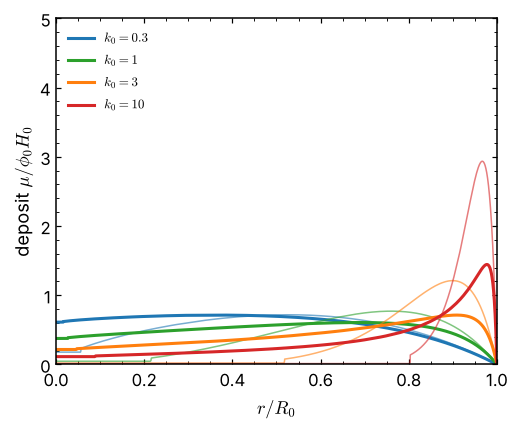

In [5]:
k0s = [0.3, 1.0, 3.0, 10.0]
print("k0 =                          " + "  ".join(f"{k:6.1f}" for k in k0s))
print("  Eq. (9.11) with k_cl = k0   " + "  ".join(f"{peak_fast(k):6.3f}" for k in k0s))
print("  constant k_cl = k0          " + "  ".join(f"{peak(drying(k, np.inf)):6.3f}" for k in k0s))
print("  constant xi_cl              " + "  ".join(f"{peak(drying(k, np.inf, constant='xi')):6.3f}" for k in k0s))

def outer_fraction(run, edge=0.8):
    r0, rf, mu = deposit(run)
    return np.sum((2 * np.pi * r0 * (1 - r0**2) / len(r0))[rf > edge]) / (math.pi / 2)

print("\nfraction of the solute deposited beyond 0.8 R0, and the height of the peak")
for k in k0s:
    runs = {c: drying(k, np.inf, constant=c) for c in ("k", "xi")}
    heights = {c: deposit(run)[2].max() for c, run in runs.items()}
    print(f"  k0 = {k:4.1f}:  constant k_cl {outer_fraction(runs['k']):.3f} (peak {heights['k']:.2f});"
          f"  constant xi_cl {outer_fraction(runs['xi']):.3f} (peak {heights['xi']:.2f})")
run = drying(3.0, np.inf, constant="xi")
ell = LOG_H0_OVER_B + np.log(run["V"] / run["R"] ** 2) - 1
k_now = 3.0 * run["V"] / run["R"] ** 3 * (LOG_H0_OVER_B - 1) / ell
for V in (1.0, 0.5, 0.1, 0.01):
    print(f"  k0 = 3, constant xi_cl: k_cl = {k_now[np.argmin(np.abs(run['V'] - V))]:.3f} when V/V0 = {V}")

fig, ax = plt.subplots(figsize=(4.6, 3.8))
for k, color in zip(k0s, ("C0", "C2", "C1", "C3")):
    r0, rf, mu = deposit(drying(k, np.inf))
    ax.plot(rf, mu, "-", color=color, lw=1, alpha=0.6)
    r0, rf, mu = deposit(drying(k, np.inf, constant="xi"))
    ax.plot(rf, mu, "-", color=color, lw=2, label=rf"$k_0 = {k:g}$")
ax.set_xlabel("$r/R_0$"); ax.set_ylabel(r"deposit $\mu/\phi_0H_0$")
ax.set_xlim(0, 1); ax.set_ylim(0, 5); ax.legend(loc="upper left", fontsize=8.5)
plt.show()

**Figure S9.3.** Fast-evaporation deposits with a constant $\xi_{\rm cl}$ (thick lines)
and with a constant $k_{\rm cl} = k_0$ (thin lines).

With a constant $\xi_{\rm cl}$ a strong ring holds much less solute and its peak is
about half as high, while its position hardly changes; a weak volcano moves inwards
(for $k_0 = 0.3$ the peak is at $0.36\,R_0$ instead of $0.53\,R_0$). The reason is that $k_{\rm cl}$ falls as
the drop flattens: for $k_0 = 3$ it is 1.9 when half the liquid has gone and 0.7 when
a tenth is left. The line friction stays the same, but the viscous friction of the
wedge, $3\eta\ell/\theta$, grows as the angle falls, so the line friction matters less
and less. Early in the drying the edge is held firmly, and the solute caught then
forms a ring at the edge. Later the edge recedes more freely, and the solute that
is left is spread over the inner part of the drop. A measured ring therefore
reflects mainly the line friction at the start of drying, when the drop is still
steep.